# XGBoost robustness check: does VIX matter?
**Claim to support:** the value of VIXCLS in Elastic Net (EN) is not a quirk of a linear model. If dropping VIX also hurts XGBoost out-of-sample, the VIX result is robust.

Per ETF (XLB, XLE, XLF, XLI, XLY), expanding window, we compare `EN` vs `EN_noVIX` and `XGB` vs `XGB_noVIX`, plus `XGB_VIXonly` vs `XGB_noMacro` (does VIX alone help?).
Evaluation: **MSE** and **QLIKE** on realised variance, then **Diebold-Mariano** tests of *noVIX vs full* within each model family.

Only two files are saved to `forecasting/results/`: `e4_losses.csv` (XGBoost losses by model and ETF, including pooled results) and `e4_evaluation.csv` (all four B4 pairs: loss ratios, test statistics and p-values). Other tables and plots are displayed without separate exports.


In [8]:
import sys
from pathlib import Path

_checkout = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models" / "research_config.py").is_file()),
    None,
)
if _checkout is None:
    raise FileNotFoundError("Start the notebook kernel from within this project checkout.")
sys.path.insert(0, str(_checkout / "models"))
from utils.paths import PROJECT_ROOT, MODELS_DIR, DATASET_DIR, FORECAST_DIR, FORECAST_RESULTS_DIR

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# ---- CONFIG ----
from research_config import BLOCKS, TICKERS
block = BLOCKS["B4"]
# walk up from the notebook's folder until we find research_config.py (the models/ folder)
FORECAST_DIR = MODELS_DIR / "forecasting" / "forecasts"
XGB_FILE = FORECAST_DIR / "xgb_forecasts.csv"
EN_FILE  = FORECAST_DIR / "en_forecasts.csv"
RESULTS_DIR = FORECAST_RESULTS_DIR
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
# label -> model name in the CSVs
MODELS = {"EN":"en_full_macro", "EN_noVIX":"en_no_vix", "EN_noMacro":"en_no_macro",
          "XGB":"xgb_full_macro", "XGB_noVIX":"xgb_no_vix", "XGB_noMacro":"xgb_no_macro", "XGB_VIXonly":"xgb_vix_only"}
# (full, restricted) pairs: positive loss diff = first one is better
PAIRS = {"EN: full vs no VIX":("EN","EN_noVIX"), "XGB: full vs no VIX":("XGB","XGB_noVIX"),
         "XGB: VIX-only vs no macro":("XGB_VIXonly","XGB_noMacro")}


## Models used

We compare seven forecast sets, all expanding-window, per ETF (XLB, XLE, XLF, XLI, XLY), on a common sample of months.

| Label | Model name in CSV | File |
|---|---|---|
| EN | `en_full_macro` | EN |
| EN_noVIX | `en_no_vix` | EN |
| EN_noMacro | `en_no_macro` | EN |
| XGB | `xgb_full_macro` | XGB |
| XGB_noVIX | `xgb_no_vix` | XGB |
| XGB_noMacro | `xgb_no_macro` | XGB |
| XGB_VIXonly | `xgb_vix_only` | XGB |

**Excluded:** the EN models with HAR terms (`en_full_macro_har`, `en_no_macro_har`, `en_no_vix_har`) and `ols_har_no_macro`. They are not part of the VIX comparison, and the `_har` EN versions start later, which would shorten the common sample.

## Comparisons tested

| Test | Full model | Restricted model | Question |
|---|---|---|---|
| EN: full vs no VIX | EN | EN_noVIX | Does VIX improve Elastic Net? |
| XGB: full vs no VIX | XGB | XGB_noVIX | Does VIX improve XGBoost (robustness check)? |
| XGB: VIX-only vs no macro | XGB_VIXonly | XGB_noMacro | Does VIX alone add value over no macro variables? |

All three pairs are nested, so the headline tests are Clark–West on log MSE and Diebold–Mariano on QLIKE. All p-values are one-sided and use Newey–West standard errors, with the lag chosen automatically by the Andrews (1991) rule.
The exported evaluation uses `research_config.BLOCKS["B4"]`: B4.0 full vs no macro,
B4.1 full vs no VIX, B4.2 VIX-only vs no macro, and B4.3 full vs VIX-only.
The EN comparisons above remain in-notebook corroboration diagnostics.


In [9]:
f = pd.concat([pd.read_csv(XGB_FILE), pd.read_csv(EN_FILE)], ignore_index=True)
f["date"] = pd.to_datetime(f["date"])
f = f[f.model.isin(MODELS.values())].copy()           
f["model"] = f.model.map({v:k for k,v in MODELS.items()})
assert not f.duplicated(["model","etf","date"]).any()

wide = f.pivot(index=["date","etf"], columns="model", values="fc_level")[list(MODELS)].dropna()  # common sample
target = f.drop_duplicates(["date","etf"]).set_index(["date","etf"])["actual_RV"]
df = wide.join(target.rename("target"))

# NEW: log-scale forecasts and actuals, on the same common sample
logs = f.pivot(index=["date","etf"], columns="model", values="fc_log")[list(MODELS)].loc[df.index]
actual_log = f.drop_duplicates(["date","etf"]).set_index(["date","etf"])["actual_logRV"].loc[df.index]

chk = f.groupby(["date","etf"]).actual_RV.agg(["min","max"]); assert np.allclose(chk["min"], chk["max"], rtol=1e-6), "models disagree on actual_RV"
assert (df[list(MODELS)] > 0).all().all()
print(df.groupby("etf").size().rename("n").to_frame().T)
print("Common sample:", df.index.get_level_values(0).min().date(), "->", df.index.get_level_values(0).max().date())

etf  XLB  XLE  XLF  XLI  XLY
n    214  214  214  214  214
Common sample: 2008-02-29 -> 2025-11-30


## 1. Loss functions
- **MSE** = mean((RV − F)²). Squared error on the level, so a few high-vol months (2008, 2020) dominate.
- **QLIKE** = mean(RV/F − log(RV/F) − 1) (Patton 2011). Robust to noisy RV proxies and penalises under-prediction more than over-prediction, so it is the more reliable ranking here.
Lower is better for both.

In [10]:
def mse(y,F):   return (y-F)**2
def qlike(y,F): return y/F - np.log(y/F) - 1

L = {}
for name,fn in {"MSE":mse,"QLIKE":qlike}.items():
    L[name] = pd.DataFrame({m: fn(df.target, df[m]) for m in MODELS})

# NEW: MSE on log realised variance (the scale the models were trained on)
L["MSE_log"] = pd.DataFrame({m: (actual_log - logs[m])**2 for m in MODELS})

def summ(loss):
    per = loss.groupby(level="etf").mean()
    per.loc["ALL (avg)"] = per.mean()
    return per

for name in L: #for each loss it diplays the table of ave losses (lower better)
    t = summ(L[name])
    print(f"\n=== mean {name} ===")
    display(t.round(8) if name == "MSE" else t.round(4)) #MSE is small so 8 dec.

# loss reduction (%) from the full model, per ETF (positive = richer model is better)
for loss in ["MSE", "MSE_log", "QLIKE"]:
    for k,(full,restr) in PAIRS.items():
        r = 1 - L[loss][full].groupby(level="etf").mean()/L[loss][restr].groupby(level="etf").mean() ## percentage improvement from VIX
        print(f"\n{loss} | {k}: relative loss reduction")
        print((100*r).round(1).astype(str)+"%")


=== mean MSE ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.000124,0.000067,0.000064,0.000077,0.000080,0.000079,0.000075
XLE,0.000233,0.000238,0.000214,0.000274,0.000272,0.000274,0.000257
XLF,0.000299,0.000376,0.000167,0.000296,0.000290,0.000253,0.000242
XLI,0.000055,0.000055,0.000054,0.000057,0.000060,0.000060,0.000056
XLY,0.000179,0.000040,0.000037,0.000052,0.000055,0.000048,0.000047
ALL (avg),0.000178,0.000155,0.000107,0.000151,0.000151,0.000143,0.000135



=== mean QLIKE ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.2837,0.3172,0.2962,0.3046,0.3421,0.3579,0.3065
XLE,0.3932,0.4148,0.2966,0.4285,0.4505,0.4104,0.3729
XLF,0.4022,0.4537,0.4052,0.4501,0.5066,0.4741,0.4524
XLI,0.2973,0.4407,0.3424,0.3180,0.3725,0.3636,0.3255
XLY,0.3066,0.3424,0.2990,0.2934,0.3442,0.3208,0.3175
ALL (avg),0.3366,0.3938,0.3279,0.3589,0.4032,0.3854,0.3550



=== mean MSE_log ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.4198,0.4645,0.4621,0.4348,0.4945,0.5304,0.4533
XLE,0.5408,0.5505,0.4524,0.5411,0.5766,0.5934,0.5646
XLF,0.5772,0.6376,0.6655,0.6077,0.6572,0.7407,0.6603
XLI,0.4387,0.5965,0.5302,0.4463,0.5185,0.5544,0.4496
XLY,0.4796,0.5367,0.5056,0.4613,0.5067,0.5337,0.5267
ALL (avg),0.4912,0.5571,0.5232,0.4982,0.5507,0.5905,0.5309



MSE | EN: full vs no VIX: relative loss reduction
etf
XLB     -86.9%
XLE       2.1%
XLF      20.4%
XLI      -1.2%
XLY    -346.7%
dtype: object

MSE | XGB: full vs no VIX: relative loss reduction
etf
XLB     3.3%
XLE    -0.7%
XLF    -2.1%
XLI     4.6%
XLY     5.8%
dtype: object

MSE | XGB: VIX-only vs no macro: relative loss reduction
etf
XLB    5.1%
XLE    6.1%
XLF    4.4%
XLI    6.6%
XLY    2.6%
dtype: object

MSE_log | EN: full vs no VIX: relative loss reduction
etf
XLB     9.6%
XLE     1.8%
XLF     9.5%
XLI    26.4%
XLY    10.6%
dtype: object

MSE_log | XGB: full vs no VIX: relative loss reduction
etf
XLB    12.1%
XLE     6.2%
XLF     7.5%
XLI    13.9%
XLY     8.9%
dtype: object

MSE_log | XGB: VIX-only vs no macro: relative loss reduction
etf
XLB    14.5%
XLE     4.9%
XLF    10.9%
XLI    18.9%
XLY     1.3%
dtype: object

QLIKE | EN: full vs no VIX: relative loss reduction
etf
XLB    10.6%
XLE     5.2%
XLF    11.3%
XLI    32.5%
XLY    10.4%
dtype: object

QLIKE | XGB: full vs no VI

## 2. Diebold-Mariano tests and Clark-West test
Loss differential d_t = L(restricted) − L(richer). Positive mean ⇒ the richer model (with VIX) is better. H0: equal predictive accuracy; one-sided H1: the VIX model is better.
Uses a Newey–West variance with the lag chosen by the Andrews (1991) rule. p-values come from the standard normal.


In [11]:
def andrews_bandwidth(x):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    den = float(xd[:-1] @ xd[:-1])
    rho = 0.0 if den <= 0 else float(xd[1:] @ xd[:-1]) / den
    rho = min(max(rho, -0.97), 0.97)
    a1 = 4.0 * rho**2 / ((1 - rho)**2 * (1 + rho)**2)
    return 0 if a1 <= 0 else int(min(np.floor(1.1447 * (a1 * n) ** (1/3)), n // 4))

def newey_west_lrv(x, lag):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    lag = max(0, min(lag, n - 1)); s = float(xd @ xd) / n
    for l in range(1, lag + 1):
        s += 2.0 * (1.0 - l / (lag + 1.0)) * float(xd[l:] @ xd[:-l]) / n
    return max(s, 1e-16)

def hac_t(d):
    d = np.asarray(d, float)
    return d.mean() / np.sqrt(newey_west_lrv(d, andrews_bandwidth(d)) / len(d))

In [12]:
def dm_test(d, lag=None, h=1):
    d = np.asarray(d, float)
    st = hac_t(d)
    return st, 1-stats.norm.cdf(st), d.mean()
            

def star(p): return "***" if p<.01 else "**" if p<.05 else "*" if p<.10 else ""

rows=[]
for loss in L:
    for k,(full,restr) in PAIRS.items():
        d_all = L[loss][restr] - L[loss][full]
        groups = {e:g.values for e,g in d_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = d_all.groupby(level="date").mean().values
        for e,d in groups.items():
            st,p,m = dm_test(d)
            rows.append(dict(loss=loss, family=k, etf=e, mean_diff=m, DM=st, p_one_sided=p, sig=star(p)))
dm = pd.DataFrame(rows)
display(dm.pivot_table(index="etf", columns=["loss","family"], values="DM").round(2))
display(dm.pivot_table(index="etf", columns=["loss","family"], values="p_one_sided").round(3))

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              -0.33                      1.54   
XLB                                -1.12                      1.08   
XLE                                 1.48                      1.43   
XLF                                 0.38                      0.36   
XLI                                -0.09                      1.83   
XLY                                -1.04                      0.72   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)                0.04               3.82   
XLB                                  1.19               2.76   
XLE                                 -0.26               1.45   
XLF                                 -0.59               2.58   
XLI                                  1.57               2.42   
XLY                                  0.89               3.47   

loss                                                                 \
family                XGB: VIX-only vs no macro XGB: full vs no VIX   
etf                                                                   
ALL (avg across ETFs)                      3.46                2.85   
XLB                                        3.15                2.95   
XLE                                        1.13                1.32   
XLF                                        2.60                1.77   
XLI                                        4.96                2.78   
XLY                                        0.28                1.90   

loss                               QLIKE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)               1.72                      3.14   
XLB                                 1.51                      3.18   
XLE                                 1.18                      1.06   
XLF                                 0.97                      1.19   
XLI                                 1.87                      3.19   
XLY                                 2.85                      0.21   

loss                                       
family                XGB: full vs no VIX  
etf                                        
ALL (avg across ETFs)                1.58  
XLB                                  2.10  
XLE                                  1.04  
XLF                                  1.38  
XLI                                  1.43  
XLY                                  1.53

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.630                     0.062   
XLB                                0.869                     0.139   
XLE                                0.069                     0.077   
XLF                                0.353                     0.358   
XLI                                0.534                     0.034   
XLY                                0.851                     0.236   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)               0.484              0.000   
XLB                                 0.116              0.003   
XLE                                 0.604              0.073   
XLF                                 0.723              0.005   
XLI                                 0.058              0.008   
XLY                                 0.186              0.000   

loss                                                                 \
family                XGB: VIX-only vs no macro XGB: full vs no VIX   
etf                                                                   
ALL (avg across ETFs)                     0.000               0.002   
XLB                                       0.001               0.002   
XLE                                       0.129               0.093   
XLF                                       0.005               0.038   
XLI                                       0.000               0.003   
XLY                                       0.390               0.029   

loss                               QLIKE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.043                     0.001   
XLB                                0.066                     0.001   
XLE                                0.119                     0.145   
XLF                                0.166                     0.118   
XLI                                0.031                     0.001   
XLY                                0.002                     0.419   

loss                                       
family                XGB: full vs no VIX  
etf                                        
ALL (avg across ETFs)               0.057  
XLB                                 0.018  
XLE                                 0.150  
XLF                                 0.084  
XLI                                 0.077  
XLY                                 0.063

In [ ]:
# XGBoost vs Elastic Net, matched on the same inputs 
CROSS = {"Full macro: XGB vs EN": ("XGB", "EN"),
         "No VIX: XGB vs EN":     ("XGB_noVIX", "EN_noVIX"),
         "No macro: XGB vs EN":   ("XGB_noMacro", "EN_noMacro")}

rows = []
for loss in L:
    for k,(xgb,en) in CROSS.items():
        d_all = L[loss][en] - L[loss][xgb]          # positive = XGBoost better
        groups = {e:g.values for e,g in d_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = d_all.groupby(level="date").mean().values
        for e,d in groups.items():
            st,_,m = dm_test(d)
            p2 = 2*(1 - stats.norm.cdf(abs(st))) if not np.isnan(st) else np.nan   # two-sided p-values (diagnostic check), one-sided tests used in the report is in notebook e5
            rows.append(dict(loss=loss, comparison=k, etf=e, mean_diff=m, DM=st, p_two_sided=p2, sig=star(p2/2)))
dm_x = pd.DataFrame(rows)
display(dm_x.pivot_table(index="etf", columns=["loss","comparison"], values="DM").round(2))
display(dm_x.pivot_table(index="etf", columns=["loss","comparison"], values="p_two_sided").round(3))

loss                                    MSE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                  0.49              0.16   
XLB                                    0.91             -1.63   
XLE                                   -1.77             -1.76   
XLF                                    0.03              0.63   
XLI                                   -0.26             -1.19   
XLY                                    0.96             -1.25   

loss                                                    MSE_log  \
comparison            No macro: XGB vs EN Full macro: XGB vs EN   
etf                                                               
ALL (avg across ETFs)               -1.82                 -0.36   
XLB                                 -2.40                 -0.70   
XLE                                 -1.61                 -0.01   
XLF                                 -1.88                 -0.90   
XLI                                 -1.74                 -0.26   
XLY                                 -1.92                  0.54   

loss                                                         \
comparison            No VIX: XGB vs EN No macro: XGB vs EN   
etf                                                           
ALL (avg across ETFs)              0.29               -2.63   
XLB                               -1.29               -2.58   
XLE                               -0.65               -2.93   
XLF                               -0.52               -2.02   
XLI                                1.12               -0.75   
XLY                                0.70               -1.04   

loss                                  QLIKE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 -1.32             -0.64   
XLB                                   -1.42             -1.85   
XLE                                   -1.12             -1.59   
XLF                                   -1.33             -1.78   
XLI                                   -0.70              1.42   
XLY                                    0.36             -0.06   

loss                                       
comparison            No macro: XGB vs EN  
etf                                        
ALL (avg across ETFs)               -2.07  
XLB                                 -1.94  
XLE                                 -1.74  
XLF                                 -2.22  
XLI                                 -0.99  
XLY                                 -1.20

loss                                    MSE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 0.626             0.877   
XLB                                   0.363             0.104   
XLE                                   0.077             0.079   
XLF                                   0.976             0.527   
XLI                                   0.797             0.235   
XLY                                   0.339             0.212   

loss                                                    MSE_log  \
comparison            No macro: XGB vs EN Full macro: XGB vs EN   
etf                                                               
ALL (avg across ETFs)               0.069                 0.717   
XLB                                 0.016                 0.486   
XLE                                 0.107                 0.992   
XLF                                 0.061                 0.367   
XLI                                 0.082                 0.793   
XLY                                 0.054                 0.590   

loss                                                         \
comparison            No VIX: XGB vs EN No macro: XGB vs EN   
etf                                                           
ALL (avg across ETFs)             0.772               0.008   
XLB                               0.195               0.010   
XLE                               0.516               0.003   
XLF                               0.605               0.044   
XLI                               0.263               0.451   
XLY                               0.483               0.299   

loss                                  QLIKE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 0.187             0.524   
XLB                                   0.156             0.064   
XLE                                   0.264             0.112   
XLF                                   0.182             0.076   
XLI                                   0.485             0.155   
XLY                                   0.717             0.948   

loss                                       
comparison            No macro: XGB vs EN  
etf                                        
ALL (avg across ETFs)               0.039  
XLB                                 0.052  
XLE                                 0.081  
XLF                                 0.026  
XLI                                 0.324  
XLY                                 0.230

In [14]:
# Clark-West test for nested models: H1 = the richer model (with VIX) forecasts better
def cw_series(y, F_restr, F_full):
    # adjusted loss differential: restricted loss minus (full loss minus the noise adjustment)
    return (y - F_restr)**2 - ((y - F_full)**2 - (F_restr - F_full)**2)

CW_DATA = {"MSE":     (df.target, df),      # level variance
           "MSE_log": (actual_log, logs)}   # log variance

rows = []
for loss,(y,F) in CW_DATA.items():
    for k,(full,restr) in PAIRS.items():
        f_all = cw_series(y, F[restr], F[full])
        groups = {e:g.values for e,g in f_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = f_all.groupby(level="date").mean().values
        for e,f_ in groups.items():
            st,p,m = dm_test(f_)        # tests mean(f_) > 0 with Newey-West variance
            rows.append(dict(loss=loss, family=k, etf=e, CW=st, p_one_sided=p, sig=star(p)))
cw = pd.DataFrame(rows)
display(cw.pivot_table(index="etf", columns=["loss","family"], values="CW").round(2))
display(cw.pivot_table(index="etf", columns=["loss","family"], values="p_one_sided").round(3))

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)               1.40                      1.79   
XLB                                -0.39                      2.08   
XLE                                 1.47                      2.54   
XLF                                 1.28                      0.83   
XLI                                 1.32                      2.43   
XLY                                 0.99                      1.99   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)                1.60               3.66   
XLB                                  1.95               4.87   
XLE                                  0.45               1.54   
XLF                                  0.75               4.08   
XLI                                  2.32               2.39   
XLY                                  1.51               3.81   

loss                                                                 
family                XGB: VIX-only vs no macro XGB: full vs no VIX  
etf                                                                  
ALL (avg across ETFs)                      6.34                4.88  
XLB                                        5.10                4.50  
XLE                                        3.04                1.99  
XLF                                        4.83                3.64  
XLI                                        6.58                3.92  
XLY                                        3.60                3.64

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.080                     0.036   
XLB                                0.650                     0.019   
XLE                                0.070                     0.006   
XLF                                0.100                     0.203   
XLI                                0.093                     0.008   
XLY                                0.161                     0.023   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)               0.055              0.000   
XLB                                 0.026              0.000   
XLE                                 0.326              0.062   
XLF                                 0.227              0.000   
XLI                                 0.010              0.008   
XLY                                 0.065              0.000   

loss                                                                 
family                XGB: VIX-only vs no macro XGB: full vs no VIX  
etf                                                                  
ALL (avg across ETFs)                     0.000               0.000  
XLB                                       0.000               0.000  
XLE                                       0.001               0.024  
XLF                                       0.000               0.000  
XLI                                       0.000               0.000  
XLY                                       0.000               0.000

In [15]:
LOSS_MAP = {"QLIKE": "QLIKE", "MSE_log": "MSE_log", "MSE": "MSE_level"}

parts = []
for m, name in MODELS.items():
    t = pd.DataFrame({new: L[old][m] for old, new in LOSS_MAP.items()})
    g = t.groupby(level="etf").mean().reset_index().rename(columns={"etf": "ETF"})
    g = pd.concat([g, t.mean().to_frame().T.assign(ETF="pooled")], ignore_index=True)
    g.insert(0, "model", name); parts.append(g)
vix_losses = pd.concat(parts, ignore_index=True)
vix_losses[vix_losses["model"].isin(block["models"])].to_csv(RESULTS_DIR / "e4_losses.csv", index=False)

li = vix_losses.set_index(["model", "ETF"])
etfs = sorted(df.index.get_level_values("etf").unique())
rows = []
labels = {name: label for label, name in MODELS.items()}
for pair_id, model_a, model_b, _ in block["pairs"]:
    a, b = labels[model_a], labels[model_b]
    cw_t_all = cw_series(actual_log, logs[b], logs[a])      # Clark-West; positive favours a
    dm_t_all = L["QLIKE"][b] - L["QLIKE"][a]                # positive favours a
    for etf in ["pooled"] + etfs:
        if etf == "pooled": cw_x, dm_x_ = cw_t_all.groupby(level="date").mean(), dm_t_all.groupby(level="date").mean()
        else:               cw_x, dm_x_ = cw_t_all.xs(etf, level="etf"), dm_t_all.xs(etf, level="etf")
        for loss, test, x in [("QLIKE", "DM", dm_x_), ("MSE_log", "Clark-West", cw_x)]:
            t_ = hac_t(x)
            rows.append({"pair": pair_id, "a": MODELS[a], "b": MODELS[b], "ETF": etf, "loss": loss, "test": test,
                         "loss_ratio": li.loc[(MODELS[a], etf), loss] / li.loc[(MODELS[b], etf), loss],
                         "gain_t": t_, "p_value": float(1 - stats.norm.cdf(t_))})
vix_tests = pd.DataFrame(rows)
vix_tests["pct_change"] = (vix_tests["loss_ratio"] - 1) * 100
vix_tests.to_csv(RESULTS_DIR / "e4_evaluation.csv", index=False)

def fmt_p(p): return "<0.001" if p < 0.001 else f"{p:.3f}"
print("Pooled (Clark-West on log MSE = primary; QLIKE = supporting):")
display(vix_tests[vix_tests.ETF == "pooled"].drop(columns="ETF").round(4).reset_index(drop=True))

for loss, test in [("MSE_log", "Clark-West"), ("QLIKE", "DM")]:
    s = vix_tests[vix_tests.loss == loss].copy()
    s["cell"] = [f"{r:.2f} ({fmt_p(p)})" for r, p in zip(s.loss_ratio, s.p_value)]
    s["row"] = s.pair + ": " + s.a + " vs " + s.b
    print(f"\n{loss}: loss ratio (one-sided p), {test}")
    display(s.pivot(index="row", columns="ETF", values="cell")[etfs + ["pooled"]].rename_axis(None))

Pooled (Clark-West on log MSE = primary; QLIKE = supporting):


,pair,a,b,loss,test,loss_ratio,gain_t,p_value,pct_change
0,B4.0,xgb_full_macro,xgb_no_macro,QLIKE,DM,0.9315,1.9025,0.0286,-6.8532
1,B4.0,xgb_full_macro,xgb_no_macro,MSE_log,Clark-West,0.8437,9.3668,0.0000,-15.6262
2,B4.1,xgb_full_macro,xgb_no_vix,QLIKE,DM,0.8903,1.5807,0.0570,-10.9661
3,B4.1,xgb_full_macro,xgb_no_vix,MSE_log,Clark-West,0.9048,4.8764,0.0000,-9.5217
4,B4.2,xgb_vix_only,xgb_no_macro,QLIKE,DM,0.9212,3.1379,0.0009,-7.8829
5,B4.2,xgb_vix_only,xgb_no_macro,MSE_log,Clark-West,0.8990,6.3405,0.0000,-10.0970
6,B4.3,xgb_full_macro,xgb_vix_only,QLIKE,DM,1.0112,-0.3053,0.6199,1.1178
7,B4.3,xgb_full_macro,xgb_vix_only,MSE_log,Clark-West,0.9385,6.9127,0.0000,-6.1502



MSE_log: loss ratio (one-sided p), Clark-West


ETF,XLB,XLE,XLF,XLI,XLY,pooled
B4.0: xgb_full_macro vs xgb_no_macro,0.82 (<0.001),0.91 (<0.001),0.82 (<0.001),0.81 (<0.001),0.86 (<0.001),0.84 (<0.001)
B4.1: xgb_full_macro vs xgb_no_vix,0.88 (<0.001),0.94 (0.024),0.92 (<0.001),0.86 (<0.001),0.91 (<0.001),0.90 (<0.001)
B4.2: xgb_vix_only vs xgb_no_macro,0.85 (<0.001),0.95 (0.001),0.89 (<0.001),0.81 (<0.001),0.99 (<0.001),0.90 (<0.001)
B4.3: xgb_full_macro vs xgb_vix_only,0.96 (<0.001),0.96 (<0.001),0.92 (<0.001),0.99 (<0.001),0.88 (<0.001),0.94 (<0.001)



QLIKE: loss ratio (one-sided p), DM


ETF,XLB,XLE,XLF,XLI,XLY,pooled
B4.0: xgb_full_macro vs xgb_no_macro,0.85 (0.017),1.04 (0.760),0.95 (0.288),0.87 (0.008),0.91 (0.093),0.93 (0.029)
B4.1: xgb_full_macro vs xgb_no_vix,0.89 (0.018),0.95 (0.150),0.89 (0.084),0.85 (0.077),0.85 (0.063),0.89 (0.057)
B4.2: xgb_vix_only vs xgb_no_macro,0.86 (<0.001),0.91 (0.145),0.95 (0.118),0.90 (<0.001),0.99 (0.419),0.92 (<0.001)
B4.3: xgb_full_macro vs xgb_vix_only,0.99 (0.462),1.15 (0.862),0.99 (0.475),0.98 (0.334),0.92 (0.105),1.01 (0.620)


## 3. Cumulative loss differential (does the VIX gain build up steadily or come from a few episodes?)

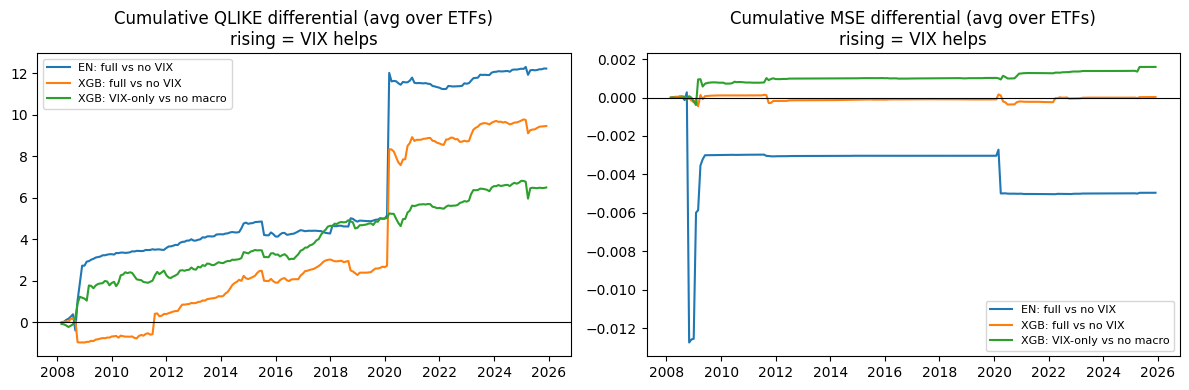

In [16]:
fig, ax = plt.subplots(1,2, figsize=(12,4), sharex=True)
for a,loss in zip(ax,["QLIKE","MSE"]):
    for k,(full,restr) in PAIRS.items():
        d = (L[loss][restr]-L[loss][full]).groupby(level="date").mean()
        a.plot(d.cumsum(), label=k)
    a.axhline(0,color="k",lw=.8); a.set_title(f"Cumulative {loss} differential (avg over ETFs)\nrising = VIX helps"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Results interpretation (auto-generated from the numbers above)

In [17]:
def verdict(k, loss):
    r = dm[(dm.loss==loss)&(dm.family==k)]
    allrow = r[r.etf.str.startswith("ALL")].iloc[0]
    e = r[~r.etf.str.startswith("ALL")]
    return allrow, (e.mean_diff>0).sum(), (e.p_one_sided<.10).sum(), len(e)

for loss in ["QLIKE","MSE"]:
    for k in PAIRS:
        a,npos,nsig,n = verdict(k,loss)
        direction = "improves" if a.mean_diff>0 else "does NOT improve"
        print(f"- {loss} | {k}: VIX {direction} accuracy on average (DM={a.DM:.2f}, one-sided p={a.p_one_sided:.3f}{a.sig}); "
              f"better in {npos}/{n} ETFs, significantly (10%) in {nsig}/{n}.")

p = cw[cw.loss.eq("MSE_log") & cw.etf.str.startswith("ALL")].set_index("family")["p_one_sided"]
ok = p["EN: full vs no VIX"] < .05 and p["XGB: full vs no VIX"] < .05
print("\nCONCLUSION (Clark-West on log MSE):",
      "XGBoost corroborates EN: VIX adds significant out-of-sample value in both model families (robust)." if ok else
      "Evidence is not significant in at least one family: report as supportive, not conclusive.")

- QLIKE | EN: full vs no VIX: VIX improves accuracy on average (DM=1.72, one-sided p=0.043**); better in 5/5 ETFs, significantly (10%) in 3/5.
- QLIKE | XGB: full vs no VIX: VIX improves accuracy on average (DM=1.58, one-sided p=0.057*); better in 5/5 ETFs, significantly (10%) in 4/5.
- QLIKE | XGB: VIX-only vs no macro: VIX improves accuracy on average (DM=3.14, one-sided p=0.001***); better in 5/5 ETFs, significantly (10%) in 2/5.
- MSE | EN: full vs no VIX: VIX does NOT improve accuracy on average (DM=-0.33, one-sided p=0.630); better in 2/5 ETFs, significantly (10%) in 1/5.
- MSE | XGB: full vs no VIX: VIX improves accuracy on average (DM=0.04, one-sided p=0.484); better in 3/5 ETFs, significantly (10%) in 1/5.
- MSE | XGB: VIX-only vs no macro: VIX improves accuracy on average (DM=1.54, one-sided p=0.062*); better in 5/5 ETFs, significantly (10%) in 2/5.

CONCLUSION (Clark-West on log MSE): XGBoost corroborates EN: VIX adds significant out-of-sample value in both model families (r

## 5. Percentage change in loss by comparison

% change in mean loss = (loss of richer model / loss of restricted model − 1) × 100. **Negative = the richer model is better** (lower loss).

- **Pooled summary** (the slide table): five XGBoost comparisons on log MSE and QLIKE, pooled over the five ETFs.
- **By ticker:** the same comparisons for XLB, XLE, XLF, XLI and XLY.
- Displayed in this notebook; the percentage-change tables are not exported separately.

Comparisons:
1. Full (macro + VIX) vs no macro
2. Add VIX to a no-macro model
3. Add other ten to VIX
4. Add VIX to the other ten
5. Other ten alone vs no macro

In [18]:
# % change in mean loss = (loss of richer model / loss of restricted model - 1) * 100
# Negative = richer model is better.
XGB_COMPARISONS = [
    ("Full (macro + VIX) vs no macro", "XGB",         "XGB_noMacro"),
    ("Add VIX to a no-macro model",    "XGB_VIXonly", "XGB_noMacro"),
    ("Add other ten to VIX",           "XGB",         "XGB_VIXonly"),
    ("Add VIX to the other ten",       "XGB",         "XGB_noVIX"),
    ("Other ten alone vs no macro",    "XGB_noVIX",   "XGB_noMacro"),
]
fmt = lambda x: f"{x:+.1f}%".replace("-", "\u2212")

def mean_loss(loss, model):
    per_etf = L[loss][model].groupby(level="etf").mean()
    per_etf["Pooled"] = L[loss][model].mean()          # pooled = average over all ETF-months
    return per_etf

pct_rows = []
for name, a, b in XGB_COMPARISONS:
    for loss in ["MSE_log", "QLIKE"]:
        pct = (mean_loss(loss, a) / mean_loss(loss, b) - 1) * 100
        pct_rows.append(pd.DataFrame({"comparison": name, "loss": loss,
                                      "ETF": pct.index, "pct_change": pct.values}))
xgb_pct = pd.concat(pct_rows, ignore_index=True)

# 1) Pooled summary table for the slide
summary = (xgb_pct[xgb_pct.ETF == "Pooled"]
           .pivot(index="comparison", columns="loss", values="pct_change")
           .loc[[c[0] for c in XGB_COMPARISONS], ["MSE_log", "QLIKE"]]
           .rename(columns={"MSE_log": "Log MSE"}))
print("XGBoost: % change in pooled loss (negative = richer model better)")
display(summary.map(fmt).rename_axis(None))     # use .applymap on older pandas

# 2) Same thing per ticker
for loss in ["MSE_log", "QLIKE"]:
    t = (xgb_pct[xgb_pct.loss == loss]
         .pivot(index="comparison", columns="ETF", values="pct_change")
         .loc[[c[0] for c in XGB_COMPARISONS], etfs + ["Pooled"]])
    print(f"\n{loss}: % change in loss by ticker")
    display(t.map(fmt).rename_axis(None))

XGBoost: % change in pooled loss (negative = richer model better)


loss,Log MSE,QLIKE
Full (macro + VIX) vs no macro,−15.6%,−6.9%
Add VIX to a no-macro model,−10.1%,−7.9%
Add other ten to VIX,−6.2%,+1.1%
Add VIX to the other ten,−9.5%,−11.0%
Other ten alone vs no macro,−6.7%,+4.6%



MSE_log: % change in loss by ticker


ETF,XLB,XLE,XLF,XLI,XLY,Pooled
Full (macro + VIX) vs no macro,−18.0%,−8.8%,−18.0%,−19.5%,−13.6%,−15.6%
Add VIX to a no-macro model,−14.5%,−4.9%,−10.9%,−18.9%,−1.3%,−10.1%
Add other ten to VIX,−4.1%,−4.2%,−8.0%,−0.7%,−12.4%,−6.2%
Add VIX to the other ten,−12.1%,−6.2%,−7.5%,−13.9%,−8.9%,−9.5%
Other ten alone vs no macro,−6.8%,−2.8%,−11.3%,−6.5%,−5.1%,−6.7%



QLIKE: % change in loss by ticker


ETF,XLB,XLE,XLF,XLI,XLY,Pooled
Full (macro + VIX) vs no macro,−14.9%,+4.4%,−5.1%,−12.5%,−8.5%,−6.9%
Add VIX to a no-macro model,−14.4%,−9.1%,−4.6%,−10.5%,−1.0%,−7.9%
Add other ten to VIX,−0.6%,+14.9%,−0.5%,−2.3%,−7.6%,+1.1%
Add VIX to the other ten,−11.0%,−4.9%,−11.1%,−14.6%,−14.7%,−11.0%
Other ten alone vs no macro,−4.4%,+9.8%,+6.9%,+2.4%,+7.3%,+4.6%
